In [ ]:
!pip install --upgrade kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.1/69.1 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.4/160.4 kB 3.9 MB/s eta 0:00:00
  Attempting uninstall: kagglehub
    Found existing installation: kagglehub 0.3.13
    Uninstalling kagglehub-0.3.13:
      Successfully uninstalled kagglehub-0.3.13


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("orvile/wesad-wearable-stress-affect-detection-dataset")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'wesad-wearable-stress-affect-detection-dataset' dataset.
Path to dataset files: /kaggle/input/wesad-wearable-stress-affect-detection-dataset


In [ ]:
import os

os.listdir(path)

for root, dirs, files in os.walk("/"):
    if "WESAD" in dirs:
        print(os.path.join(root, "WESAD"))
        break



/root/.cache/kagglehub/datasets/orvile/wesad-wearable-stress-affect-detection-dataset/versions/1/WESAD


In [ ]:
!pip install neurokit2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 708.4/708.4 kB 17.1 MB/s eta 0:00:00


In [ ]:
import os
import pickle
import numpy as np
import neurokit2 as nk
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
BASE_PATH = "/kaggle/input/wesad-wearable-stress-affect-detection-dataset/WESAD"   # change if needed
SUBJECTS = ["S2", "S3", "S4", "S5", "S6"]  # 🔒 FIXED 5 subjects

FS = 700
WINDOW_SEC = 15
OVERLAP = 0.5

WINDOW_SAMPLES = int(WINDOW_SEC * FS)
STEP = int(WINDOW_SAMPLES * (1 - OVERLAP))




In [ ]:
def create_windows(signal, window_size, step):
    return np.array([
        signal[i:i+window_size]
        for i in range(0, len(signal) - window_size, step)
    ])


def window_labels(labels, window_size, step):
    y = []
    for i in range(0, len(labels) - window_size, step):
        y.append(np.bincount(labels[i:i+window_size]).argmax())
    return np.array(y)


def extract_hrv_features(ecg_signal, fs=700):
    try:
        _, rpeaks = nk.ecg_peaks(ecg_signal, sampling_rate=fs)
        hrv = nk.hrv_time(rpeaks, sampling_rate=fs, show=False)
        return [
            hrv["HRV_MeanNN"].values[0],
            hrv["HRV_SDNN"].values[0],
            hrv["HRV_RMSSD"].values[0]
        ]
    except:
        return [0.0, 0.0, 0.0]


def extract_eda_features(eda_signal, fs=700):
    try:
        eda_clean = nk.eda_clean(eda_signal, sampling_rate=fs)
        eda_phasic = nk.eda_phasic(eda_clean, sampling_rate=fs)
        tonic_mean = np.mean(eda_phasic["EDA_Tonic"])
        scr_peaks = nk.eda_peaks(eda_clean, sampling_rate=fs)[1]["SCR_Peaks"]
        return [tonic_mean, len(scr_peaks)]
    except:
        return [0.0, 0.0]


def extract_acc_features(acc_window):
    try:
        mag = np.sqrt(acc_window[:,0]**2 + acc_window[:,1]**2 + acc_window[:,2]**2)
        return [np.mean(mag), np.std(mag)]
    except:
        return [0.0, 0.0]



In [ ]:
X_all = []
y_all = []
subject_ids = []

label_map = {1: 0, 3: 1, 2: 2}  # Calm, Mild, Escalated

for subj in SUBJECTS:
    print(f"Processing {subj}...")

    with open(os.path.join(BASE_PATH, subj, f"{subj}.pkl"), "rb") as f:
     data = pickle.load(f, encoding="latin1")

    chest = data["signal"]["chest"]
    labels = data["label"]

    ecg = chest["ECG"].flatten()
    eda = chest["EDA"].flatten()
    acc = chest["ACC"]

    ecg_w = create_windows(ecg, WINDOW_SAMPLES, STEP)
    eda_w = create_windows(eda, WINDOW_SAMPLES, STEP)
    acc_w = create_windows(acc, WINDOW_SAMPLES, STEP)
    y_w   = window_labels(labels, WINDOW_SAMPLES, STEP)

    # Filter affective states only
    valid = np.isin(y_w, [1,2,3])
    ecg_w, eda_w, acc_w, y_w = ecg_w[valid], eda_w[valid], acc_w[valid], y_w[valid]

    # Map labels
    y_mapped = np.array([label_map[int(l)] for l in y_w])

    # Feature extraction
    hrv = np.array([extract_hrv_features(w) for w in ecg_w])
    eda_f = np.array([extract_eda_features(w) for w in eda_w])
    acc_f = np.array([extract_acc_features(w) for w in acc_w])

    X_sub = np.hstack([hrv, eda_f, acc_f])

    X_all.append(X_sub)
    y_all.append(y_mapped)
    subject_ids.extend([subj] * len(y_mapped))


Processing S2...
Processing S3...
Processing S4...
Processing S5...
Processing S6...


In [ ]:
X = np.vstack(X_all)
y = np.concatenate(y_all)
subject_ids = np.array(subject_ids)

print("Final X shape:", X.shape)
print("Final y shape:", y.shape)


Final X shape: (1447, 7)
Final y shape: (1447,)


In [ ]:
# Final system-level emotion labels
# WESAD:
# 1 -> Baseline
# 3 -> Amusement
# 2 -> Stress

# System:
# 0 -> Calm
# 1 -> Mild
# 2 -> Escalated

label_map = {
    1: 0,  # Calm
    3: 1,  # Mild
    2: 2   # Escalated
}

y_mapped = np.array([label_map[l] for l in y_windows])


In [ ]:
# Subject-wise z-score normalization
X_norm = X.copy().astype(float)

for subj in np.unique(subject_ids):
    idx = subject_ids == subj

    mu = X[idx].mean(axis=0)
    sigma = X[idx].std(axis=0) + 1e-6  # numerical stability

    X_norm[idx] = (X[idx] - mu) / sigma


In [ ]:
# Leave-One-Subject-Out (example: S6 as test subject)
test_subject = "S6"

train_idx = subject_ids != test_subject
test_idx  = subject_ids == test_subject

X_train, X_test = X_norm[train_idx], X_norm[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Train subjects:", np.unique(subject_ids[train_idx]))
print("Test subject:", np.unique(subject_ids[test_idx]))



Train subjects: ['S2' 'S3' 'S4' 'S5']
Test subject: ['S6']


In [ ]:
rf_loso = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_loso.fit(X_train, y_train)



RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [ ]:
y_pred = rf_loso.predict(X_test)

print("LOSO Accuracy (subject-wise z-score):", accuracy_score(y_test, y_pred))

print(classification_report(
    y_test,
    y_pred,
    target_names=["Calm", "Mild", "Escalated"]
))


LOSO Accuracy (subject-wise z-score): 0.8843537414965986
              precision    recall  f1-score   support

        Calm       0.90      0.93      0.91       158
        Mild       0.68      0.65      0.67        49
   Escalated       0.98      0.93      0.95        87

    accuracy                           0.88       294
   macro avg       0.85      0.84      0.84       294
weighted avg       0.88      0.88      0.88       294



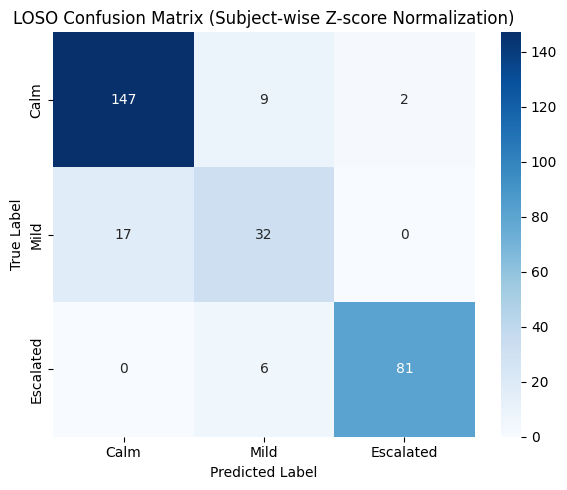

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Calm", "Mild", "Escalated"],
    yticklabels=["Calm", "Mild", "Escalated"]
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("LOSO Confusion Matrix (Subject-wise Z-score Normalization)")
plt.tight_layout()
plt.show()


In [ ]:
import joblib

# Save deployment model
joblib.dump(rf_loso, "rf_5subject_deployment.pkl")

# Save feature schema
feature_names = [
    "HRV_MeanNN",
    "HRV_SDNN",
    "HRV_RMSSD",
    "EDA_TonicMean",
    "EDA_SCR_Count",
    "ACC_MeanMag",
    "ACC_StdMag"
]
joblib.dump(feature_names, "feature_names.pkl")


['feature_names.pkl']

In [ ]:
from google.colab import files

files.download("rf_5subject_deployment.pkl")
files.download("feature_names.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>